# 05. RNN / LSTM / GRU — 순환 신경망

## 🎯 이 노트북에서 배울 것
1. 시퀀스(순서 있는 데이터)를 다루는 **순환 구조**의 원리
2. 사인파 시계열에서 "다음 값 예측"을 **RNN vs LSTM vs GRU**로 비교
3. 각 셀이 "왜" 필요한지 (기울기 소실 문제) 이해하기

## 📖 핵심 개념
- RNN: `h_t = tanh(W_x·x_t + W_h·h_{t-1} + b)` —과거의 정보가 hidden state `h`에 압축되어 전달됨
- many-to-one 구조: 시퀀스 전체를 읽고 마지막 hidden state로 예측
- **기울기 소실**: 역전파가 긴 시퀀스를 거치며 `tanh`/시그모이드 미분값(≤1)이 곱해지면서 경사가 0으로 사라짐
- **LSTM**은 cell state + 게이트(forget/input/output)로 긴 의존성을 보존, **GRU**는 이를 단순화한 버전


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록,환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

np.random.seed(0)
plt.rcParams["figure.figsize"] = (10, 4)


## 1) 데이터: 노이즈가 낀 사인파 시계열

길이 40짜리 윈도우를 입력으로 주면, 그 **다음 값 하나를 예측**하는 many-to-one문제입니다.


In [2]:
t = np.linspace(0, 40 * np.pi, 4000)
series = np.sin(t) + 0.1 * np.random.randn(len(t))   # 사인파 + 약간의 노이즈

SEQ = 40   # 입력 시퀀스 길이
X, y = [], []
for i in range(len(series) - SEQ):
    X.append(series[i:i + SEQ])       # 길이 40 구간
    y.append(series[i + SEQ])         # 그 다음 값 (정답)
X = np.array(X, dtype=np.float32).reshape(-1, SEQ, 1)  # (N, seq_len, feature=1)
y = np.array(y, dtype=np.float32).reshape(-1, 1)
n_train = int(len(X) * 0.8)           # 앞 80%는 학습, 뒤 20%는 테스트 (시계열은 순서 유지가 중요)
print("학습 샘플:", n_train, " 테스트 샘플:", len(X) - n_train)


학습 샘플: 3168  테스트 샘플: 792


## 2) RNN / LSTM / GRU 모델 정의 (PyTorch)

세 모델의 구조는 완전히 똑같고 **순환 셀 종류만** 다릅니다. 출력을 비교하면 각 셀의효과가 명확히 보입니다.


In [3]:
import torch
import torch.nn as nn

torch.manual_seed(0)

class RNNRegressor(nn.Module):
    def __init__(self, cell="RNN", hidden=32):
        super().__init__()
        # nn.RNN / nn.LSTM / nn.GRU: (batch, seq, feature) 형태 입력 (batch_first=True)
        cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = cls(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)   # 마지막 hidden state → 다음 실수 값 예측

    def forward(self, x):
        out, h = self.rnn(x)             # out: (N, seq, hidden) — 모든 시점의 출력
        # many-to-one: 시퀀스의 '마지막 시점' 출력만분류/회귀에 사용
        # (LSTM의 h는 (h, c) 튜플이고형태이 (층, 배치, 은닉)이라 out을 쓰는 게 더 직관적)
        return self.fc(out[:, -1, :])

def train_model(model, epochs=40, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()               # 회귀 문제이므로 MSE 손실
    Xtr = torch.tensor(X[:n_train]); ytr = torch.tensor(y[:n_train])
    losses = []
    for ep in range(epochs):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xtr), ytr)  # 전체 학습 데이터를 한 번에 (작은 데이터라 full-batch 가능)
        loss.backward()                  # BPTT: Time을 거슬러 올라가며 역전파 (Backprop Through Time)
        opt.step()
        losses.append(loss.item())
    return losses


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

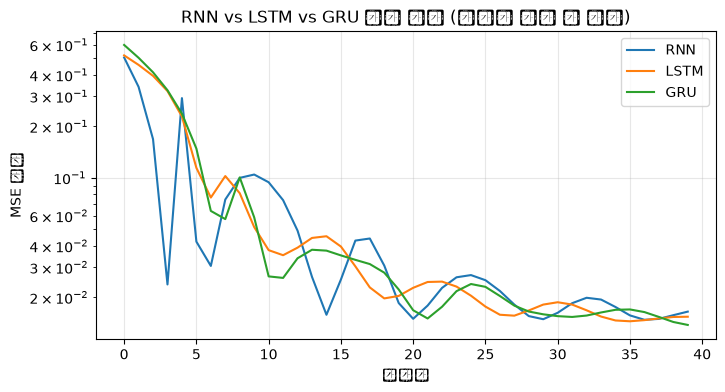

RNN: 최종 손실 = 0.01647
LSTM: 최종 손실 = 0.01538
GRU: 최종 손실 = 0.01376


In [4]:
models = {name: RNNRegressor(name) for name in ["RNN", "LSTM", "GRU"]}
hist = {name: train_model(m) for name, m in models.items()}

plt.figure(figsize=(8, 4))
for name, losses in hist.items():
    plt.plot(losses, label=name)
plt.xlabel("에포크"); plt.ylabel("MSE 손실"); plt.yscale("log")
plt.title("RNN vs LSTM vs GRU 학습 곡선 (사인파 다음 값 예측)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
for name, losses in hist.items():
    print(f"{name}: 최종 손실 = {losses[-1]:.5f}")


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53580 (\N{HANGUL SYLLABLE TE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

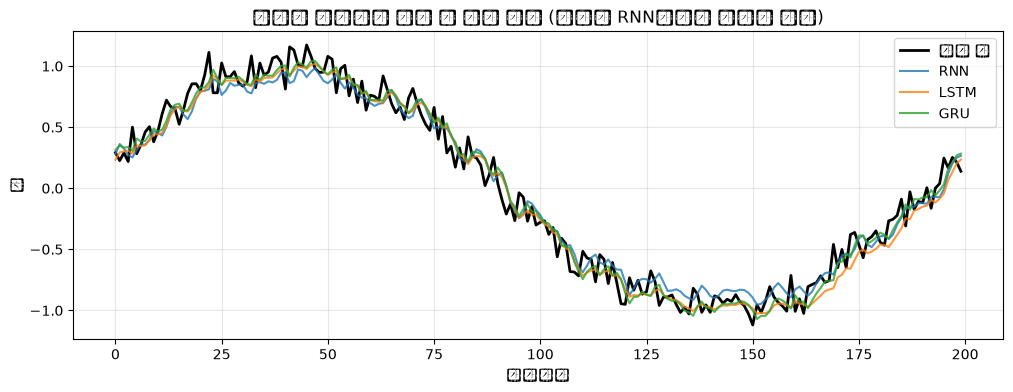

In [5]:
# 테스트 구간에서 '다음 값 예측' 비교
Xte = torch.tensor(X[n_train:]); yte = y[n_train:]
plt.figure(figsize=(12, 4))
plt.plot(yte[:200], color="black", lw=2, label="실제 값")
with torch.no_grad():
    for name, m in models.items():
        m.eval()
        plt.plot(m(Xte)[:200].numpy(), label=name, alpha=0.8)
plt.title("테스트 구간에서 다음 값 예측 비교 (바닐라 RNN은장기 패턴을 놓침)")
plt.xlabel("타임스텝"); plt.ylabel("값"); plt.legend(); plt.grid(alpha=0.3); plt.show()


## ✅ 정리

- RNN은 hidden state로과거 정보를 전달하지만, 긴 시퀀스에서는 **기울기 소실**로 옛날 정보가 사라짐
- **LSTM**은 게이트와 cell state로장기 의존성을 보존 → 테스트 구간에서 월등히 좋은 예측
- **GRU**는 LSTM을 단순화(게이트 2개)해도 비슷한 성능, 계산이 더 가벼움
-응용: 번역, 음성인식, 시계열 예측, 텍스트 생성 등 모든 시퀀스 문제 (요즘은 Transformer가 대체하는 경우도 많음)
- 다음: [`06_GNN.ipynb`](./06_GNN.ipynb) — 그래프 구조 데이터를 위한 GNN
